# 01 · Energy + non-negativity ⇒ disentangling along the axes of a rectangular support

**Question 3 (mechanism).** *Why do we sometimes see mixed selectivity and sometimes disentanglement?*

Whittington, Dorrell, Ganguli & Behrens (ICLR 2023) proved that **non-negative** activity plus
**activity and weight energy costs** make the optimal code *disentangled* — provided the latent
factors have **rectangular support** ("range independence"). This notebook gives the mechanism in
the simplest possible form and then tests it with trained autoencoders.

### Mechanism in one line
A firing rate must be ≥ 0. To encode a signed variable $r\cdot f$ a neuron needs a baseline
$b = \max_{f\in\text{support}}(-r\cdot f)$, and baselines cost energy ($\mathbb E\|z\|^2 = \|b\|^2 + \text{rotation-invariant terms}$).
For a rectangular support $b=\sum_j |r_j|$, i.e. an **L1 norm**, which is minimised when every neuron
points along *one* axis of the rectangle. The cheapest code is therefore aligned with **whatever axes the support is rectangular in** —
the factor axes for independent or merely correlated factors, rotated axes for a rotated (diamond) support.

**Main result of this notebook:** the support's geometry, not the correlation between factors, decides; an *uncorrelated*
but rotated support makes the optimal code mixed with respect to the factors (and disentangled with respect to f1 ± f2).

In [1]:
import os, sys, json, time
import numpy as np
import torch
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath(".."))
from mixdis import data, models, metrics, dendrite, rnn
from mixdis.utils import save_json, load_json, set_threads

# FAST=1 -> tiny smoke-test run (minutes). Unset/0 -> full experiment.
FAST = os.environ.get("FAST", "0") == "1"
set_threads()
RES = os.path.abspath("../results"); os.makedirs(RES, exist_ok=True)
FIG = os.path.join(RES, "figures"); os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})
def savefig(name):
    plt.savefig(os.path.join(FIG, name + ".png"), bbox_inches="tight", dpi=200)
    plt.savefig(os.path.join(FIG, name + ".pdf"), bbox_inches="tight")
print("FAST mode:", FAST, "| torch", torch.__version__, "| threads", torch.get_num_threads())

FAST mode: False | torch 2.14.1 | threads 7


## 1. Energy landscape of a 2-neuron non-negative code

Two neurons with unit-norm encoding directions $r_1, r_2$ (angles $\theta_1,\theta_2$), each with the minimal
baseline that keeps it non-negative on the support. Cost = activity energy $\sum_i \mathbb E z_i^2$ + weight energy of
the decoder $\lambda_w\|A^{-1}\|_F^2$ (decoding must stay possible). We scan all pairs of angles.

Supports: rectangular independent; correlated (Gaussian copula, still rectangular); corner missing; and a **diamond**:
$f = R_{45°}(u,v)$ with $u,v$ independent — $f_1,f_2$ are *uncorrelated* yet dependent, and the support is rectangular
only in the rotated basis $(f_1+f_2,\ f_1-f_2)$.

independent, rectangular         optimal directions    90°,   180° | disentangled wrt (f1,f2): 1.00 | wrt (f1+f2, f1−f2): 0.02
correlated ρ=0.8, rectangular    optimal directions    96°,   177° | disentangled wrt (f1,f2): 0.99 | wrt (f1+f2, f1−f2): 0.71
independent, corner missing      optimal directions     0°,    90° | disentangled wrt (f1,f2): 1.00 | wrt (f1+f2, f1−f2): 0.36
diamond: uncorrelated, rotated support optimal directions    45°,   315° | disentangled wrt (f1,f2): 0.01 | wrt (f1+f2, f1−f2): 1.00


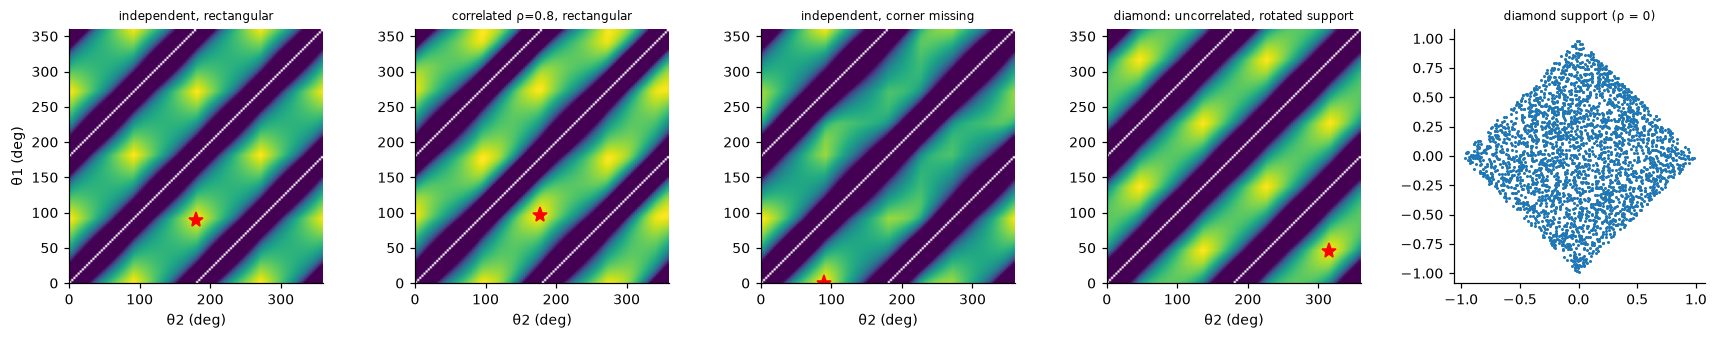

In [2]:
rng = np.random.default_rng(0)
n = 20000
SUPPORTS = {"independent, rectangular": dict(corr=0.0, support="full"),
            "correlated ρ=0.8, rectangular": dict(corr=0.8, support="full"),
            "independent, corner missing": dict(corr=0.0, support="corner"),
            "diamond: uncorrelated, rotated support": dict(corr=0.0, support="diamond")}
NA = 48 if FAST else 120
ang = np.linspace(0, 2 * np.pi, NA, endpoint=False); U = np.stack([np.cos(ang), np.sin(ang)], 1)
LW = 1.0
LAND, OPT = {}, {}
for nm, kw in SUPPORTS.items():
    F = data.sample_factors(n, 2, rng=rng, **kw)
    P = F @ U.T; e1 = ((P - P.min(0)) ** 2).mean(0)                 # energy of one neuron per direction
    C = np.full((NA, NA), np.nan)
    for i in range(NA):
        for j in range(NA):
            A = U[[i, j]]
            if abs(np.linalg.det(A)) > 0.05:
                C[i, j] = e1[i] + e1[j] + LW * (np.linalg.inv(A) ** 2).sum()
    i, j = np.unravel_index(np.nanargmin(C), C.shape)
    Fopt = F[:5000] @ U[[i, j]].T; Zopt = Fopt - Fopt.min(0)
    rot = np.c_[F[:5000, 0] + F[:5000, 1], F[:5000, 0] - F[:5000, 1]]
    OPT[nm] = dict(theta=(np.degrees(ang[i]), np.degrees(ang[j])),
                   disent_factors=metrics.disentanglement(Zopt, F[:5000], deg=1)[0],
                   disent_rotated=metrics.disentanglement(Zopt, rot, deg=1)[0])
    LAND[nm] = C
    print(f"{nm:32s} optimal directions {OPT[nm]['theta'][0]:5.0f}°, {OPT[nm]['theta'][1]:5.0f}° | "
          f"disentangled wrt (f1,f2): {OPT[nm]['disent_factors']:.2f} | wrt (f1+f2, f1−f2): {OPT[nm]['disent_rotated']:.2f}")
fig, axs = plt.subplots(1, len(SUPPORTS) + 1, figsize=(3.2 * (len(SUPPORTS) + 1), 3))
for ax, (nm, C) in zip(axs, LAND.items()):
    ax.imshow(np.log(C / np.nanmin(C)), origin="lower", extent=[0, 360, 0, 360], cmap="viridis_r", vmax=1.0)
    ax.plot(*OPT[nm]["theta"][::-1], "r*", ms=10); ax.set_title(nm, fontsize=8); ax.set_xlabel("θ2 (deg)")
axs[0].set_ylabel("θ1 (deg)")
F = data.sample_factors(3000, 2, rng=rng, support="diamond"); axs[-1].scatter(F[:, 0], F[:, 1], s=1)
axs[-1].set_title("diamond support (ρ = 0)", fontsize=8); axs[-1].set_aspect("equal")
plt.tight_layout(); savefig("01_energy_landscape"); plt.show()
E = {nm: C.min(1) for nm, C in LAND.items()}; th = ang

**Result (analytic optimum, 2 neurons).**

| support | optimal directions | disentangled w.r.t. (f1, f2) | w.r.t. (f1+f2, f1−f2) |
|---|---|---|---|
| independent, rectangular | 90°, 180° | 1.00 | 0.02 |
| correlated ρ = 0.8, rectangular | 96°, 177° | 0.99 | 0.71 |
| independent, corner missing | 0°, 90° | 1.00 | 0.36 |
| **diamond (ρ = 0, rotated support)** | **45°, 315°** | **0.01** | **1.00** |

Correlation barely moves the optimum; removing one corner does not change it either. Only rotating the support does.

## 2. Trained autoencoders: phase diagram over constraints

Observations $x = A f$ (random linear mixing into $D$=30 channels). Autoencoder $z=\phi(W_e x+b)$, $\hat x = W_d z$.
Loss = reconstruction + $\lambda_{act}\,\mathbb E z^2$ + $\lambda_w \|W\|^2$ with $\lambda_w=\lambda_{act}/10$.
$\phi$ = identity (no positivity) or ReLU (non-negative rates).

In [3]:
K = 2
H = 6
STEPS = 300 if FAST else 4000
SEEDS = [0] if FAST else [0, 1, 2, 3]
LAMS = [0.0, 1e-2] if FAST else [0.0, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1]
ACTS = ["linear", "relu"]
NS = 1500 if FAST else 4000
obs = data.RandomObservation(K, 30, "linear", seed=0)
R = {}
for sname, kw in SUPPORTS.items():
    F = data.sample_factors(NS, K, rng=np.random.default_rng(1), **kw); X = obs(F)
    for act in ACTS:
        for lam in LAMS:
            for seed in SEEDS:
                m = models.Autoencoder(30, H, act=act, seed=seed)
                h = models.train(m, X, None, "recon", steps=STEPS, act_l2=lam, w_l2=lam / 10, seed=seed)
                Z = models.hidden(m, X)
                d, _ = metrics.disentanglement(Z[:2000], F[:2000])
                rot = np.c_[F[:2000, 0] + F[:2000, 1], F[:2000, 0] - F[:2000, 1]]
                dr, _ = metrics.disentanglement(Z[:2000], rot)
                R[(sname, act, lam, seed)] = dict(disent=d, disent_rot=dr, recon=h["task_loss"][-1], **metrics.energy(Z))
            v = [R[(sname, act, lam, s)]["disent"] for s in SEEDS]
            vr = [R[(sname, act, lam, s)]["disent_rot"] for s in SEEDS]
            print(f"{sname:32s} {act:6s} λ={lam:<6g} disent {np.nanmean(v):.2f}±{np.nanstd(v):.2f} (rotated basis {np.nanmean(vr):.2f})  "
                  f"recon {np.mean([R[(sname, act, lam, s)]['recon'] for s in SEEDS]):.4f}")

independent, rectangular         linear λ=0      disent 0.57±0.07 (rotated basis 0.70)  recon 0.0000
independent, rectangular         linear λ=0.001  disent 0.60±0.13 (rotated basis 0.70)  recon 0.0000
independent, rectangular         linear λ=0.003  disent 0.60±0.13 (rotated basis 0.71)  recon 0.0000
independent, rectangular         linear λ=0.01   disent 0.61±0.13 (rotated basis 0.70)  recon 0.0001
independent, rectangular         linear λ=0.03   disent 0.62±0.15 (rotated basis 0.68)  recon 0.0010
independent, rectangular         linear λ=0.1    disent 0.68±0.13 (rotated basis 0.66)  recon 0.0113
independent, rectangular         relu   λ=0      disent 0.62±0.16 (rotated basis 0.71)  recon 0.0000
independent, rectangular         relu   λ=0.001  disent 0.64±0.20 (rotated basis 0.65)  recon 0.0000
independent, rectangular         relu   λ=0.003  disent 0.62±0.21 (rotated basis 0.68)  recon 0.0001
independent, rectangular         relu   λ=0.01   disent 0.58±0.24 (rotated basis 0.74)  rec

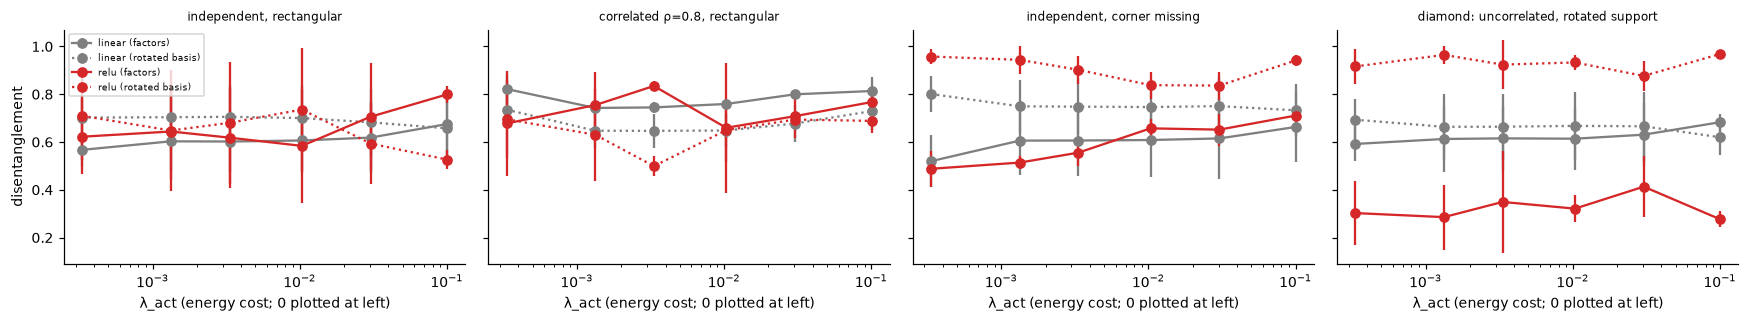

In [4]:
fig, axs = plt.subplots(1, len(SUPPORTS), figsize=(4 * len(SUPPORTS), 3), sharey=True)
for ax, sname in zip(axs, SUPPORTS):
    for act, c in zip(ACTS, ["tab:gray", "tab:red"]):
        x = np.array(LAMS) + (LAMS[1] / 3 if len(LAMS) > 1 else 1e-4)
        for key, ls in [("disent", "-"), ("disent_rot", ":")]:
            M = np.array([[R[(sname, act, l, s)][key] for s in SEEDS] for l in LAMS])
            ax.errorbar(x, np.nanmean(M, 1), np.nanstd(M, 1), marker="o", color=c, ls=ls,
                        label=f"{act} ({'factors' if key == 'disent' else 'rotated basis'})")
    ax.set_xscale("log"); ax.set_xlabel("λ_act (energy cost; 0 plotted at left)"); ax.set_title(sname, fontsize=8)
axs[0].set_ylabel("disentanglement"); axs[0].legend(fontsize=6); plt.tight_layout(); savefig("01_constraints_phase_diagram"); plt.show()

**Result (trained autoencoders, 4 seeds, 6 latent units).**

* **Linear latents** (no positivity) show no preferred basis on any support (disentanglement 0.52–0.82 w.r.t. the factors and
  0.62–0.80 w.r.t. the rotated basis, with no consistent ordering): without non-negativity the code is only defined up to rotation.
* **Diamond support, ReLU:** mixed with respect to the factors (0.28–0.41) and disentangled with respect to f1 ± f2 (0.88–0.97)
  at **every** energy level, including λ = 0. Non-negativity plus the support geometry is enough; mixed selectivity here is an efficient
  factorised code of different latent variables.
* **Rectangular support, ReLU:** disentanglement rises with the energy cost, from 0.62 ± 0.16 (λ = 0) to 0.80 ± 0.03 (λ = 0.1),
  at the price of reconstruction error (0.000 → 0.025). Energy makes the factorised solution reliable across seeds.
* **Correlated, rectangular (ρ = 0.8), ReLU:** 0.66–0.83 with large seed variance; no systematic effect of correlation.
* **Corner missing, ReLU:** trained codes align *more* with the rotated basis (0.84–0.96) than with the factors (0.49–0.71), unlike the
  2-neuron analytic optimum. With 6 units the network can place one unit along the diagonal edge created by the missing corner;
  this discrepancy is an open point to analyse (e.g. by the energy of the 6-unit optimum).

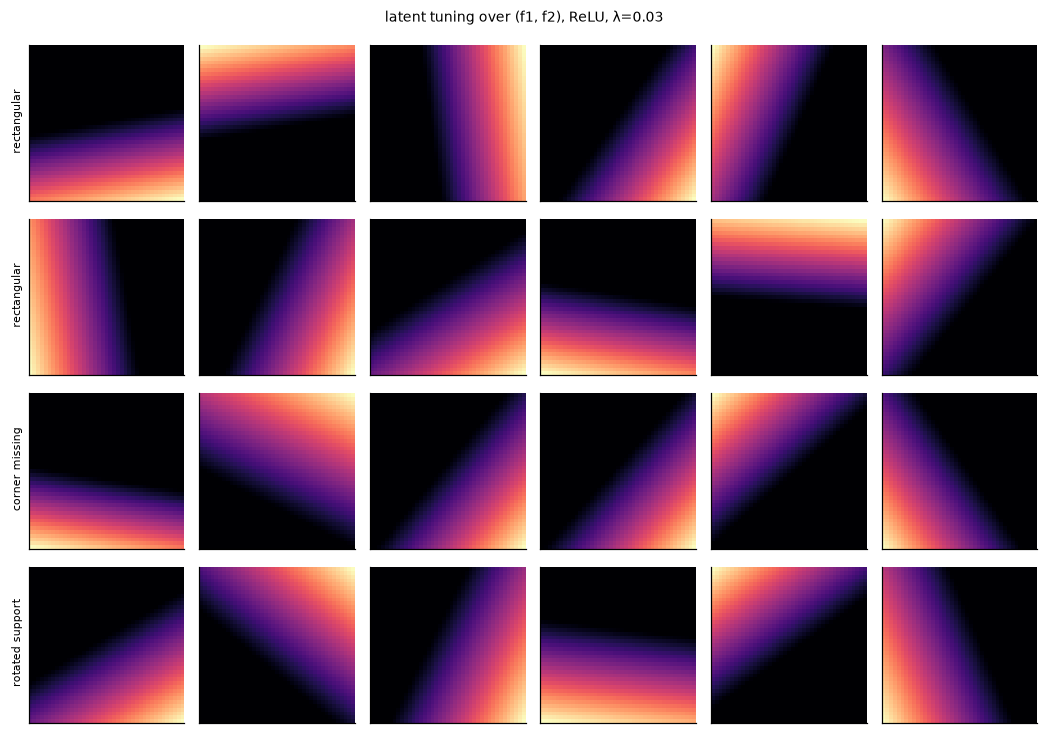

In [5]:
# Tuning maps of the latents for the most-constrained ReLU model on each support
lam = LAMS[-2] if len(LAMS) > 2 else LAMS[-1]
fig, axs = plt.subplots(len(SUPPORTS), H, figsize=(1.6 * H, 1.7 * len(SUPPORTS)))
g = np.linspace(-1, 1, 41); GG = np.stack(np.meshgrid(g, g), -1).reshape(-1, 2).astype(np.float32)
for r, (sname, kw) in enumerate(SUPPORTS.items()):
    F = data.sample_factors(NS, K, rng=np.random.default_rng(1), **kw); X = obs(F)
    m = models.Autoencoder(30, H, act="relu", seed=0)
    models.train(m, X, None, "recon", steps=STEPS, act_l2=lam, w_l2=lam / 10)
    Zg = models.hidden(m, obs(GG))
    for j in range(H):
        axs[r, j].imshow(Zg[:, j].reshape(41, 41), origin="lower", extent=[-1, 1, -1, 1], cmap="magma")
        axs[r, j].set_xticks([]); axs[r, j].set_yticks([])
    axs[r, 0].set_ylabel(sname.split(",")[-1], fontsize=7)
plt.suptitle(f"latent tuning over (f1, f2), ReLU, λ={lam}", fontsize=9); plt.tight_layout(); savefig("01_latent_tuning_maps"); plt.show()
save_json({"R": {"|".join(map(str, k)): v for k, v in R.items()}, "LAMS": LAMS, "E": {k: v for k, v in E.items()},
           "theta": th, "OPT": OPT}, os.path.join(RES, "nb01_energy.json"))

### Summary of notebook 01
* The energy-optimal non-negative code aligns with the axes in which the joint support of the latent variables is rectangular.
* Correlation does not produce mixing; a rotated support does, even with zero correlation. Trained ReLU autoencoders follow this
  (diamond: 0.28–0.41 vs 0.88–0.97 in the rotated basis), linear autoencoders show no preferred basis.
* Energy costs make the factorised solution robust for rectangular supports (0.62 ± 0.16 → 0.80 ± 0.03).
* Open point: corner-missing supports push trained 6-unit codes towards the diagonal, contrary to the 2-neuron optimum.
* Prediction for experiments: neurons should be "mixed" for pairs of variables whose joint range is restricted along a diagonal,
  regardless of their correlation, and "pure" for variables that can vary independently over their whole range.